# Palantir: Controlling Fate Probabilities with Absorption Rates

This notebook demonstrates Palantir's absorption rate feature, which provides explicit
control over the fate probability balance at terminal states.

### Background

In the standard Palantir pipeline, `determine_multiscale_space` rescales diffusion
components to implicitly regularize the starting fate probabilities toward a more
balanced distribution. While effective, this is an indirect mechanism — the rescaling
changes the geometry of the entire manifold.

**Absorption rates** provide a more direct and interpretable alternative. Each terminal
state is assigned a rate α ∈ (0, 1] that controls how "sticky" it is: the random walk
is absorbed with probability α at each visit and continues with probability 1 − α. By
lowering the absorption rate of over-represented fates (or raising under-represented
ones), we can explicitly steer the fate probability vector at any reference cell toward a
desired target — without modifying the underlying manifold.

`optimize_absorption_rates` automates this: it finds the rates that best match a target
fate distribution (uniform by default) at a reference cell (the start cell by default).

### Outline

1. Load and preprocess data (same as standard pipeline)
2. Compute diffusion maps — **skip `determine_multiscale_space`**
3. Run Palantir with default (full) absorption → observe imbalanced fates
4. Optimize absorption rates → re-run with balanced fates
5. Compare results and explore custom targets

## Imports

In [1]:
import palantir
import scanpy as sc
import numpy as np
import pandas as pd
import os

import matplotlib
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings(action="ignore", message=".*sparsity.*")
warnings.filterwarnings(action="ignore", message=".*np.find_common_type.*")
warnings.filterwarnings(action="ignore", message=".*No data for colormapping.*")

%matplotlib inline

## Loading and preprocessing data

Standard preprocessing: normalize, log-transform, HVG selection, PCA.

In [2]:
download_url = "https://dp-lab-data-public.s3.amazonaws.com/palantir/marrow_sample_scseq_counts.h5ad"
file_path = "marrow_sample_scseq_counts.h5ad"
ad = sc.read(file_path, backup_url=download_url)

sc.pp.normalize_total(ad)
palantir.preprocess.log_transform(ad)
sc.pp.highly_variable_genes(ad, n_top_genes=1500, flavor="cell_ranger")
sc.pp.pca(ad)
ad

AnnData object with n_obs × n_vars = 4142 × 16106
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'

## Diffusion maps — without multiscale rescaling

We compute diffusion maps but **skip `determine_multiscale_space`**. Instead, we pass
the raw diffusion eigenvectors directly to Palantir via `eigvec_key="DM_EigenVectors"`.

The multiscale step rescales eigenvectors by `λ/(1−λ)` which also implicitly regularizes fate
probabilities. With absorption rate optimization we achieve the same goal explicitly.

In [3]:
dm_res = palantir.utils.run_diffusion_maps(ad, n_components=5)

### Visualization

In [4]:
sc.pp.neighbors(ad)
sc.tl.umap(ad)

/Users/dotto/gits/Palantir/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
imputed_X = palantir.utils.run_magic_imputation(ad)

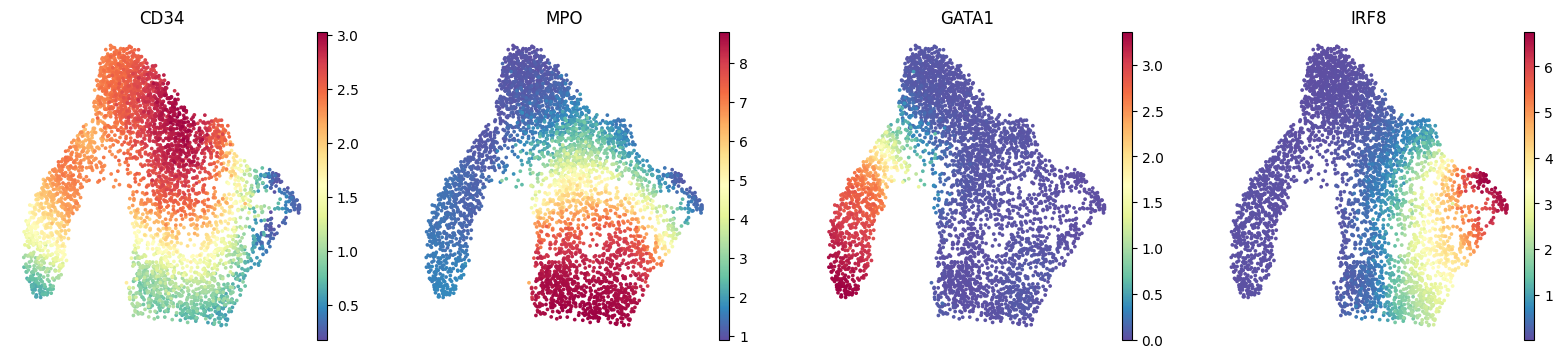

In [6]:
sc.pl.embedding(
    ad, basis="umap", layer="MAGIC_imputed_data",
    color=["CD34", "MPO", "GATA1", "IRF8"], frameon=False,
)
plt.show()

## Define terminal states and start cell

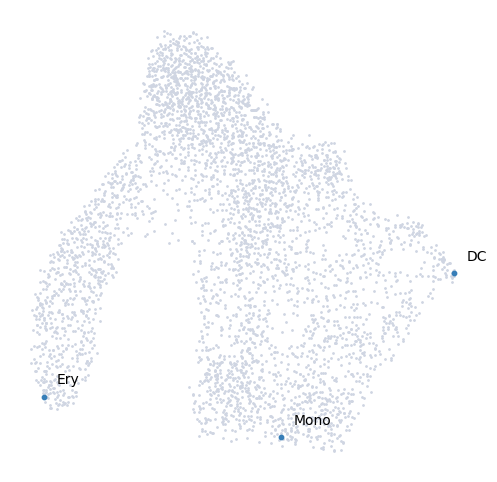

In [7]:
terminal_states = pd.Series(
    ["DC", "Mono", "Ery"],
    index=["Run5_131097901611291", "Run5_134936662236454", "Run4_200562869397916"],
)
start_cell = "Run5_164698952452459"

palantir.plot.highlight_cells_on_umap(ad, terminal_states)
plt.show()

## Step 1: Run Palantir with default absorption rates (all 1.0)

Using raw diffusion eigenvectors (`eigvec_key="DM_EigenVectors"`) without multiscale
rescaling. With full absorption (the default), the fate probabilities at the start cell
will likely be imbalanced — one lineage may dominate.

In [8]:
pr_res_default = palantir.core.run_palantir(
    ad, start_cell,
    num_waypoints=500,
    terminal_states=terminal_states,
    eigvec_key="DM_EigenVectors",
    pseudo_time_key="palantir_pseudotime_default",
    entropy_key="palantir_entropy_default",
    fate_prob_key="palantir_fate_probabilities_default",
)

Sampling and flocking waypoints...
Time for determining waypoints: 8.141597112019857e-05 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.009227216243743896 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9998
Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


### Fate probabilities at the start cell

With full absorption and no multiscale rescaling, the fate probabilities at the start
cell are typically skewed:

In [9]:
fate_at_start = pr_res_default.branch_probs.loc[start_cell]
print("Fate probabilities at start cell (default, no multiscale):")
print(fate_at_start.to_string())
print(f"\nIdeal uniform: {1/len(fate_at_start):.4f} each")

Fate probabilities at start cell (default, no multiscale):
Ery     0.260893
DC      0.199336
Mono    0.539771

Ideal uniform: 0.3333 each


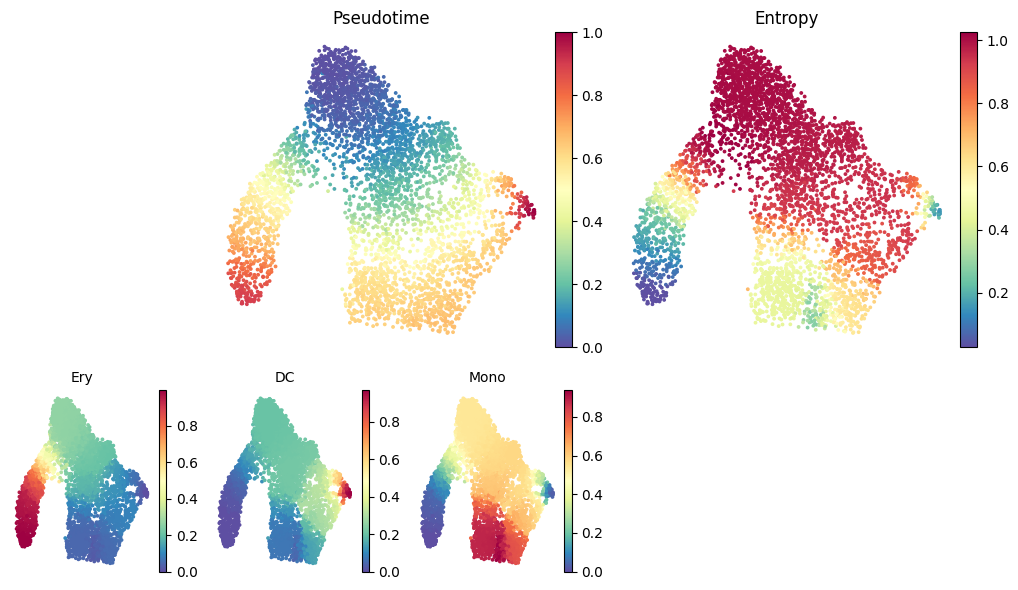

In [10]:
palantir.plot.plot_palantir_results(
    ad, s=3,
    pseudo_time_key="palantir_pseudotime_default",
    entropy_key="palantir_entropy_default",
    fate_prob_key="palantir_fate_probabilities_default",
)
plt.show()

## Step 2: Optimize absorption rates

`optimize_absorption_rates` finds absorption rates that make the fate probabilities at
the start cell match a target distribution. The default target is uniform (equal
probability for each fate).

Internally, this precomputes the expensive matrix factorization once, then optimizes
over a small k×k system (k = number of terminals) — very fast.

In [11]:
optimal_rates = palantir.utils.optimize_absorption_rates(
    ad, start_cell,
    terminal_states=terminal_states,
    num_waypoints=500,
    eigvec_key="DM_EigenVectors",
)

Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.009275718530019125 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9998
Correlation at iteration 2: 1.0000
Markov chain construction...
Optimized absorption rates:
  Run4_200562869397916: 1.0000
  Run5_131097901611291: 1.0000
  Run5_134936662236454: 0.1425
Achieved fate probs at reference cell: [0.33299909 0.33360478 0.33339613]
Target fate probs:                     [0.33333333 0.33333333 0.33333333]


## Step 3: Re-run Palantir with optimized absorption rates

In [12]:
pr_res_optimized = palantir.core.run_palantir(
    ad, start_cell,
    num_waypoints=500,
    terminal_states=terminal_states,
    eigvec_key="DM_EigenVectors",
    absorption_rates=optimal_rates,
)

Sampling and flocking waypoints...
Time for determining waypoints: 8.366902669270833e-05 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.009257133801778157 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9998
Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


In [13]:
fate_optimized = pr_res_optimized.branch_probs.loc[start_cell]
print("Fate probabilities at start cell (optimized absorption rates):")
print(fate_optimized.to_string())
print(f"\nTarget (uniform): {1/len(fate_optimized):.4f} each")

Fate probabilities at start cell (optimized absorption rates):
Ery     0.332699
DC      0.333760
Mono    0.333541

Target (uniform): 0.3333 each


### Comparing default vs optimized results

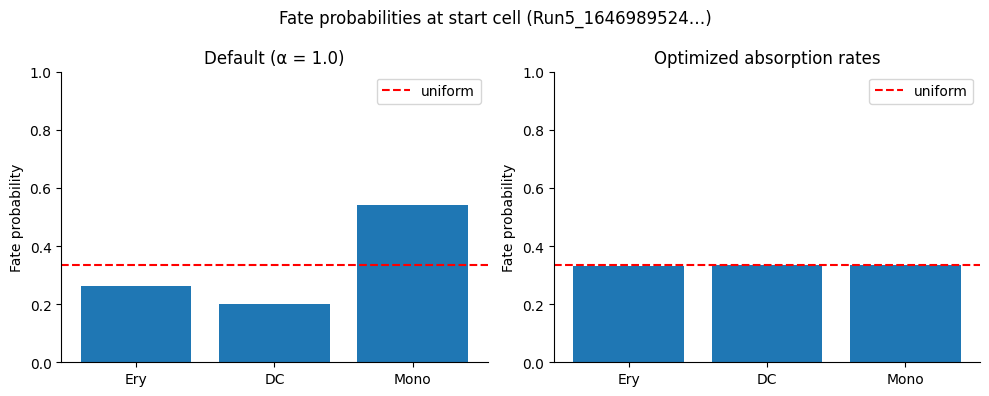

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

fate_default = pr_res_default.branch_probs.loc[start_cell]
fate_opt = pr_res_optimized.branch_probs.loc[start_cell]
labels = fate_default.index

axes[0].bar(labels, fate_default.values)
axes[0].set_title("Default (α = 1.0)")
axes[0].set_ylabel("Fate probability")
axes[0].set_ylim(0, 1)
axes[0].axhline(1/len(labels), color="red", ls="--", label="uniform")
axes[0].legend()

axes[1].bar(labels, fate_opt.values)
axes[1].set_title("Optimized absorption rates")
axes[1].set_ylabel("Fate probability")
axes[1].set_ylim(0, 1)
axes[1].axhline(1/len(labels), color="red", ls="--", label="uniform")
axes[1].legend()

fig.suptitle(f"Fate probabilities at start cell ({start_cell[:15]}…)", fontsize=12)
plt.tight_layout()
plt.show()

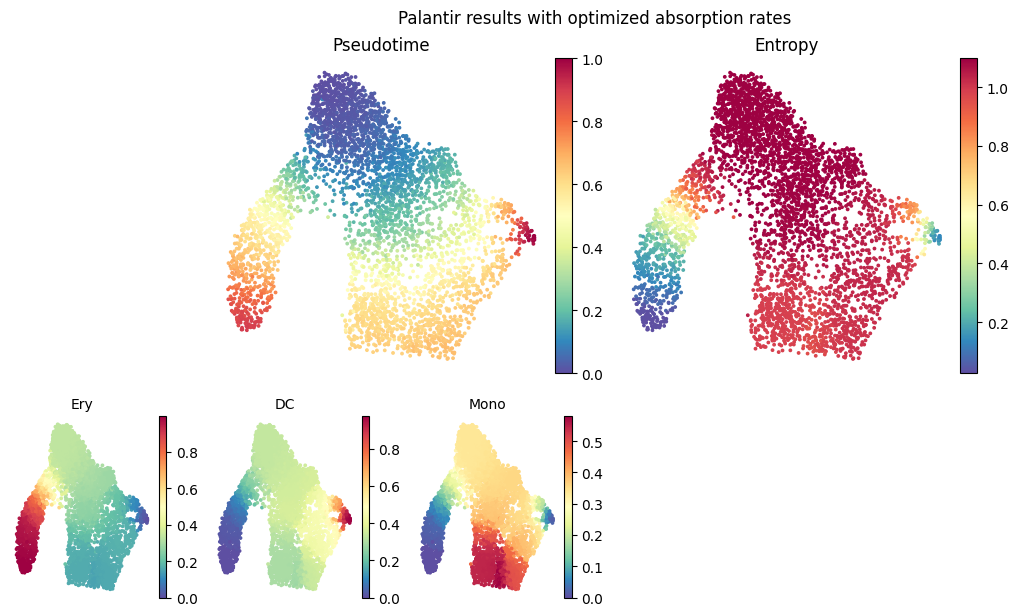

In [15]:
palantir.plot.plot_palantir_results(ad, s=3)
plt.suptitle("Palantir results with optimized absorption rates", y=1.02)
plt.show()

### Visualizing terminal state probabilities along the trajectory

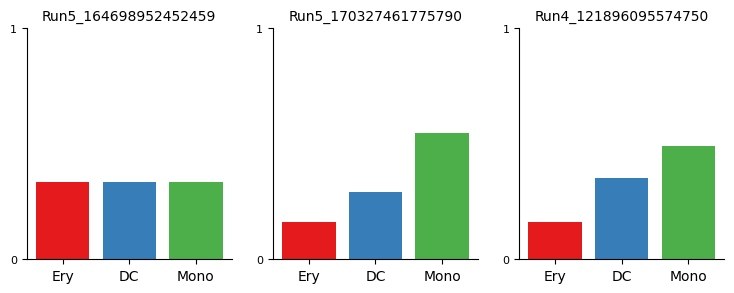

In [16]:
cells = [
    "Run5_164698952452459",  # start cell
    "Run5_170327461775790",
    "Run4_121896095574750",
]
palantir.plot.plot_terminal_state_probs(ad, cells)
plt.show()

## Step 4: Encoding expected stem-cell fate probabilities

The default optimization target is uniform — equal probability for every fate at the
start cell. But biology often dictates otherwise: a hematopoietic stem cell may
preferentially commit to one lineage over another. If you know (e.g. from lineage
tracing, clone-size distributions, or prior literature) that the stem-cell population
produces 60 % erythroid, 20 % monocyte, and 20 % dendritic cells, you can encode that
directly via `target_fate_probs`.

The `target_fate_probs` vector has one entry per terminal state **in the same order as
`terminal_states`**. The optimizer then finds absorption rates that reproduce those
expected proportions at the start cell, anchoring the entire fate-probability landscape
to the known biology.

In [17]:
# Suppose lineage-tracing tells us the HSC compartment yields
# 60% erythroid, 20% monocyte, and 20% dendritic cells.
# The target vector follows the terminal_states order:
print("Terminal states order:", list(terminal_states.values))

#                                         DC   Mono  Ery
custom_target = np.array([                0.2, 0.2,  0.6])

custom_rates = palantir.utils.optimize_absorption_rates(
    ad, start_cell,
    terminal_states=terminal_states,
    target_fate_probs=custom_target,
    num_waypoints=500,
    eigvec_key="DM_EigenVectors",
)

Terminal states order: ['DC', 'Mono', 'Ery']
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.008884652455647787 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9998
Correlation at iteration 2: 1.0000
Markov chain construction...
Optimized absorption rates:
  Run4_200562869397916: 0.0162
  Run5_131097901611291: 0.3269
  Run5_134936662236454: 1.0000
Achieved fate probs at reference cell: [0.20000055 0.19999946 0.59999998]
Target fate probs:                     [0.2 0.2 0.6]


In [18]:
pr_res_custom = palantir.core.run_palantir(
    ad, start_cell,
    num_waypoints=500,
    terminal_states=terminal_states,
    eigvec_key="DM_EigenVectors",
    absorption_rates=custom_rates,
    pseudo_time_key="palantir_pseudotime_custom",
    entropy_key="palantir_entropy_custom",
    fate_prob_key="palantir_fate_probabilities_custom",
)

fate_custom = pr_res_custom.branch_probs.loc[start_cell]
print("Achieved fate probabilities at start cell:")
for name, prob, target in zip(terminal_states.values, fate_custom.values, custom_target):
    print(f"  {name:5s}  {prob:.4f}  (target {target:.2f})")

Sampling and flocking waypoints...
Time for determining waypoints: 7.82012939453125e-05 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.00906448761622111 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9998
Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...
Achieved fate probabilities at start cell:
  DC     0.1997  (target 0.20)
  Mono   0.2001  (target 0.20)
  Ery    0.6002  (target 0.60)


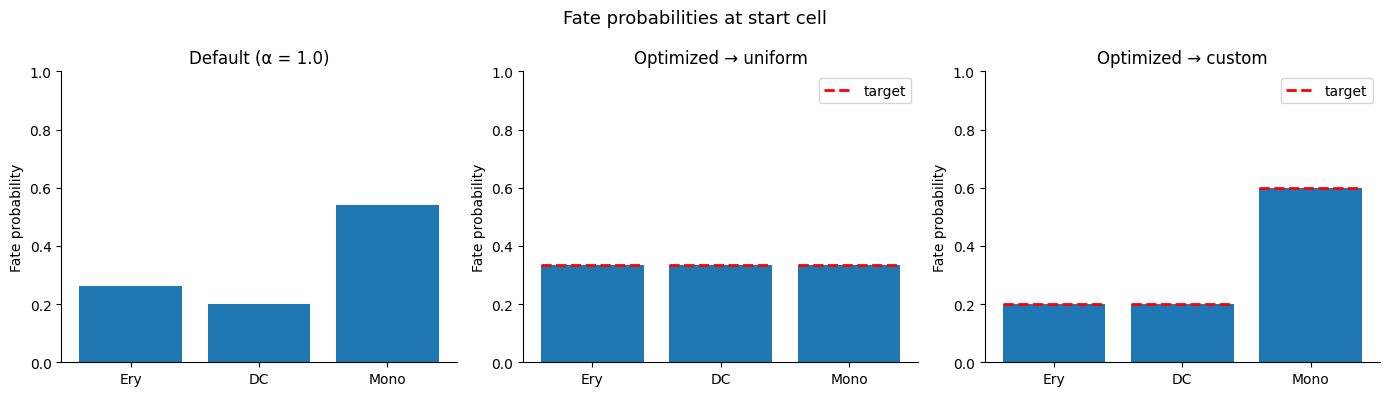

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
labels = fate_default.index

for ax, (title, vals, target) in zip(axes, [
    ("Default (α = 1.0)", fate_default.values, None),
    ("Optimized → uniform", fate_opt.values, np.ones(len(labels)) / len(labels)),
    ("Optimized → custom", fate_custom.values, custom_target),
]):
    ax.bar(labels, vals)
    ax.set_title(title)
    ax.set_ylabel("Fate probability")
    ax.set_ylim(0, 1)
    if target is not None:
        for i, t in enumerate(target):
            ax.plot([i - 0.4, i + 0.4], [t, t], "r--", lw=2,
                    label="target" if i == 0 else None)
        ax.legend()

fig.suptitle(f"Fate probabilities at start cell", fontsize=13)
plt.tight_layout()
plt.show()

## Step 5: Manual absorption rates

You can also set absorption rates manually without optimization. For example, to make
the erythroid terminal less absorbing:

In [20]:
manual_rates = {
    "Run5_131097901611291": 1.0,   # DC — full absorption
    "Run5_134936662236454": 1.0,   # Mono — full absorption
    "Run4_200562869397916": 0.3,   # Ery — leaky (30% absorption per visit)
}

pr_res_manual = palantir.core.run_palantir(
    ad, start_cell,
    num_waypoints=500,
    terminal_states=terminal_states,
    eigvec_key="DM_EigenVectors",
    absorption_rates=manual_rates,
    pseudo_time_key="palantir_pseudotime_manual",
    entropy_key="palantir_entropy_manual",
    fate_prob_key="palantir_fate_probabilities_manual",
)

print("Fate probabilities at start cell (manual rates):")
print(pr_res_manual.branch_probs.loc[start_cell].to_string())

Sampling and flocking waypoints...
Time for determining waypoints: 8.213520050048828e-05 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.010322733720143636 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9998
Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...
Fate probabilities at start cell (manual rates):
Ery     0.257727
DC      0.200175
Mono    0.542097


## Gene expression trends

Using the optimized (uniform) absorption rates for downstream analysis.

In [21]:
# Re-run with optimized rates so ad stores the optimized results
pr_res = palantir.core.run_palantir(
    ad, start_cell,
    num_waypoints=500,
    terminal_states=terminal_states,
    eigvec_key="DM_EigenVectors",
    absorption_rates=optimal_rates,
)

masks = palantir.presults.select_branch_cells(ad, q=0.01, eps=0.01)

Sampling and flocking waypoints...
Time for determining waypoints: 7.941325505574544e-05 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.008966052532196045 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9998
Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


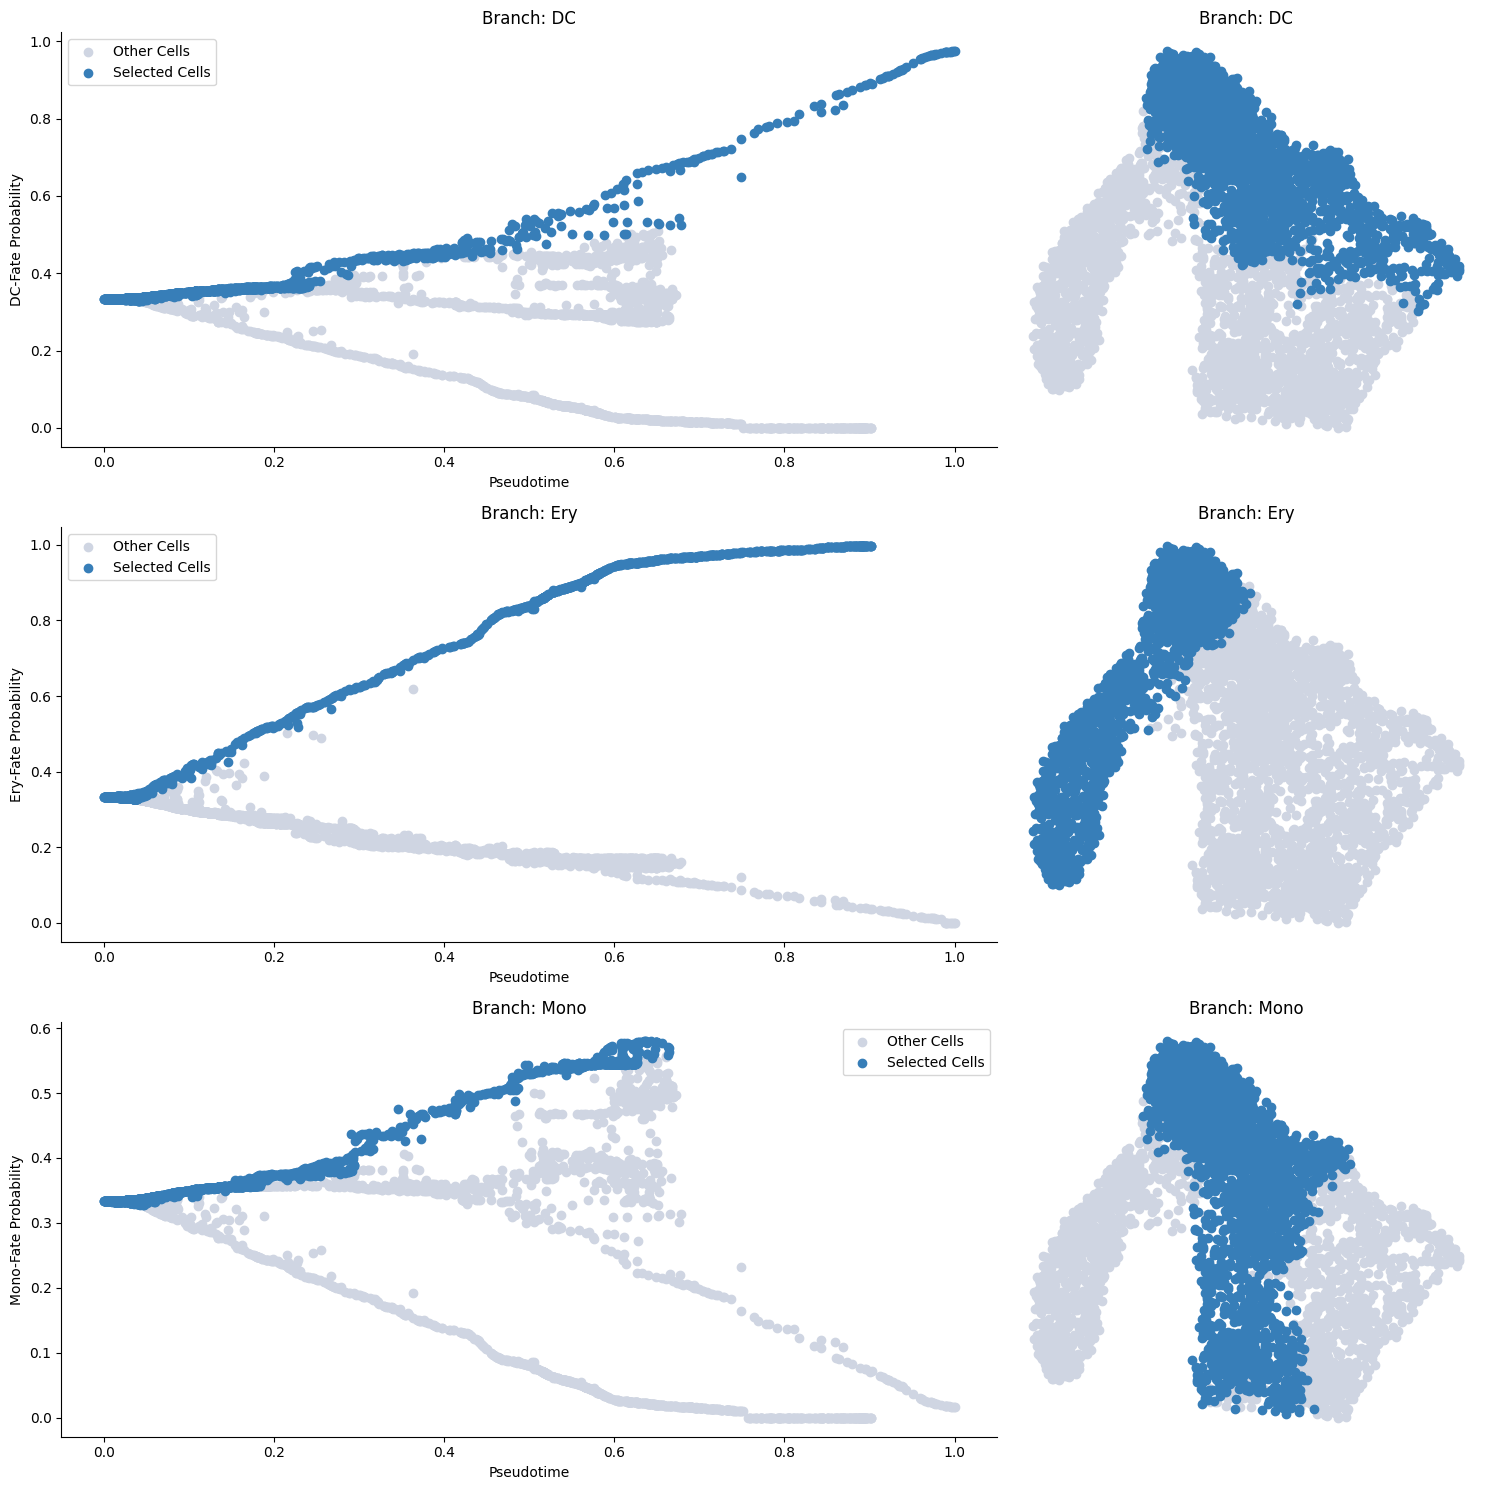

In [22]:
palantir.plot.plot_branch_selection(ad)
plt.show()

In [23]:
gene_trends = palantir.presults.compute_gene_trends(
    ad, expression_key="MAGIC_imputed_data",
)

/Users/dotto/gits/Palantir/src/palantir/presults.py:270: FutureWarning: Use obs (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`) instead of AnnData.obs_keys, AnnData.obs_keys is deprecated and will be removed in the future.
  if pseudo_time_key not in ad.obs_keys():


Ery
[2026-03-04 19:22:42,010] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (1,557) and rank = 1.0.
[2026-03-04 19:22:42,010] [INFO    ] Using covariance function Matern52(ls=1.0).


W0304 19:22:42.303832 21244122 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.


[2026-03-04 19:22:42,855] [INFO    ] Sigma interpreted as element-wise standard deviation.
DC
[2026-03-04 19:22:43,237] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (2,043) and rank = 1.0.
[2026-03-04 19:22:43,238] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-03-04 19:22:43,557] [INFO    ] Sigma interpreted as element-wise standard deviation.
Mono
[2026-03-04 19:22:43,800] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (2,341) and rank = 1.0.
[2026-03-04 19:22:43,801] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-03-04 19:22:44,131] [INFO    ] Sigma interpreted as element-wise standard deviation.


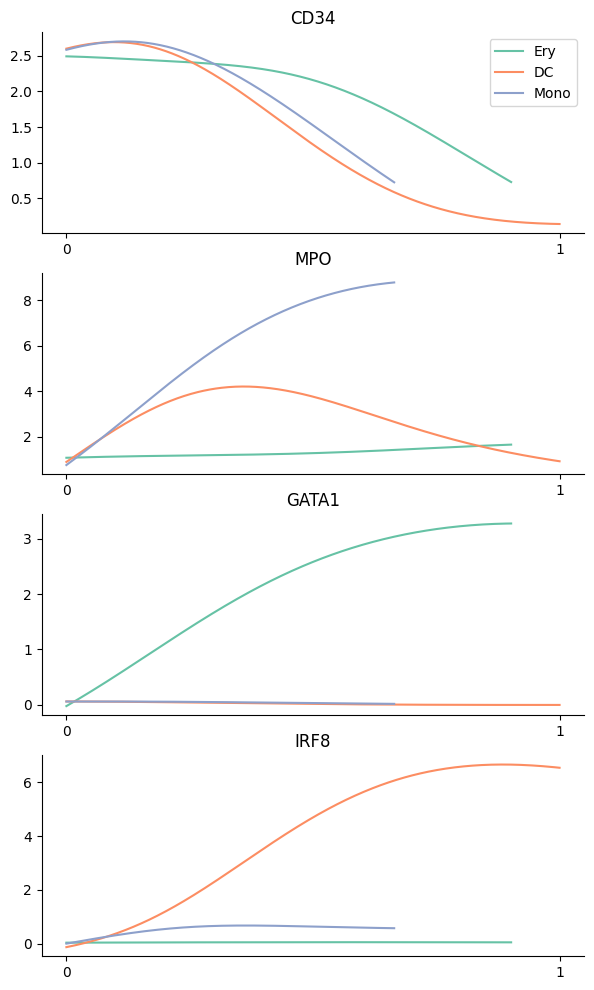

In [24]:
genes = ["CD34", "MPO", "GATA1", "IRF8"]
palantir.plot.plot_gene_trends(ad, genes)
plt.show()

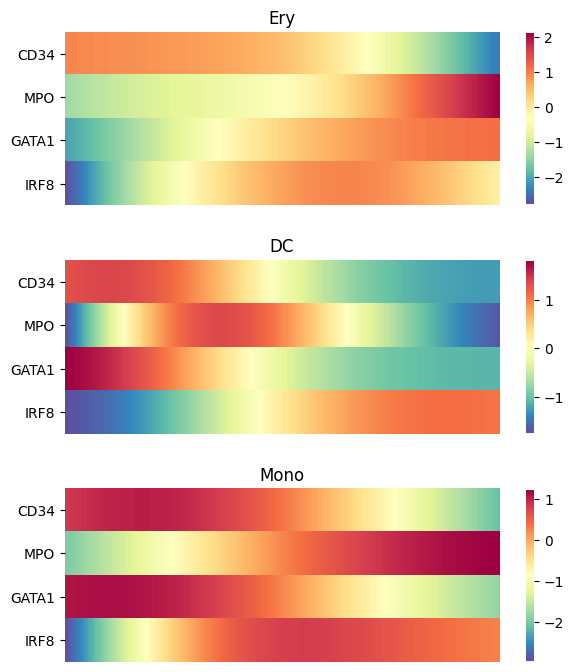

In [25]:
palantir.plot.plot_gene_trend_heatmaps(ad, genes)
plt.show()